In [1]:
import numpy as np
import pandas as pd

In [186]:
df = pd.read_csv('data/train.csv')

In [187]:
df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [188]:
df.shape

(1460, 81)

In [189]:
df = df.drop(columns=['PoolQC','MiscFeature','Fence','Alley','MasVnrType','FireplaceQu'])

In [190]:
df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].mean())

In [191]:
import seaborn as sns
import matplotlib.pyplot as plt

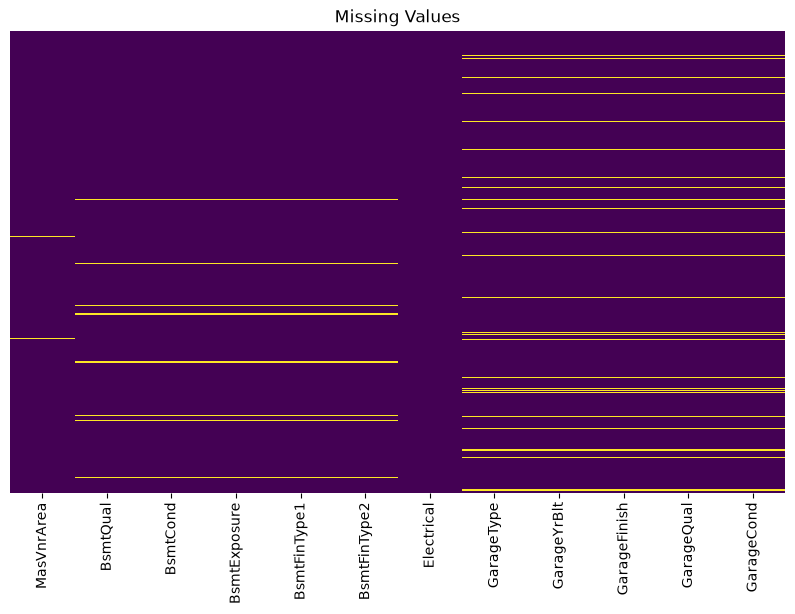

In [192]:
missing_cols = df.columns[df.isnull().any()]

plt.figure(figsize=(10, 6))

sns.heatmap(
    df[missing_cols].isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values")
plt.show()

In [193]:
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,...,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,...,0,0,0,0,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,...,0,0,0,0,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,...,272,0,0,0,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,...,0,0,0,0,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,Reg,Lvl,AllPub,Inside,...,112,0,0,0,0,4,2010,WD,Normal,142125


In [194]:
df['GarageCond'] = df['GarageCond'].fillna("NoGaradge")
df['GarageType'] = df['GarageType'].fillna("NoGaradge")
df['GarageYrBlt'] = df['GarageYrBlt'].fillna("NoGaradge")
df['GarageFinish'] = df['GarageFinish'].fillna("NoGaradge")
df['GarageQual'] = df['GarageQual'].fillna("NoGaradge")

df['BsmtQual'] = df['BsmtQual'].fillna("NoBsmt")
df['BsmtCond'] = df['BsmtCond'].fillna("NoBsmt")
df['BsmtExposure'] = df['BsmtExposure'].fillna("NoBsmt")
df['BsmtFinType1'] = df['BsmtFinType1'].fillna("NoBsmt")
df['BsmtFinType2'] = df['BsmtFinType2'].fillna("NoBsmt")


In [195]:
df = df.dropna()

In [196]:
test_df = pd.read_csv('data/test.csv')

In [197]:
test_df = test_df.drop(columns=['PoolQC','MiscFeature','Fence','Alley','MasVnrType','FireplaceQu'])
test_df['LotFrontage'] = test_df['LotFrontage'].fillna(test_df['LotFrontage'].mean())
test_df['GarageCond'] = test_df['GarageCond'].fillna("NoGaradge")
test_df['GarageType'] = test_df['GarageType'].fillna("NoGaradge")
test_df['GarageYrBlt'] = test_df['GarageYrBlt'].fillna("NoGaradge")
test_df['GarageFinish'] = test_df['GarageFinish'].fillna("NoGaradge")
test_df['GarageQual'] = test_df['GarageQual'].fillna("NoGaradge")

test_df['BsmtQual'] = test_df['BsmtQual'].fillna("NoBsmt")
test_df['BsmtCond'] = test_df['BsmtCond'].fillna("NoBsmt")
test_df['BsmtExposure'] = test_df['BsmtExposure'].fillna("NoBsmt")
test_df['BsmtFinType1'] = test_df['BsmtFinType1'].fillna("NoBsmt")
test_df['BsmtFinType2'] = test_df['BsmtFinType2'].fillna("NoBsmt")

In [198]:
df.shape

(1451, 75)

In [199]:
test_df.shape

(1459, 74)

In [200]:
Y = df['SalePrice']
train_df = df.drop(columns =['SalePrice'])

In [201]:
# y = train['SalePrice']

# train_features = train.drop('SalePrice', axis=1)

combined = pd.concat([train_df, test_df], axis=0)

categorical_cols = combined.select_dtypes(
    include=['object', 'category']
).columns

combined = pd.get_dummies(
    combined,
    columns=categorical_cols,
    dtype=int
)

n_train = len(df)

train_df = combined.iloc[:n_train].copy()
test_df = combined.iloc[n_train:].copy()

C:\Users\aryan\AppData\Local\Temp\ipykernel_10076\3144134008.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = combined.select_dtypes(


In [202]:
train_df.shape

(1451, 379)

In [203]:
test_df.shape

(1459, 379)

In [204]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    train_df,
    Y,
    test_size=0.2,
    random_state=42
)

In [205]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_tr, y_tr)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](379,)","[ 1.71, -30. , 63.12,..., 425.79, 7436.87,-34080.94]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](379,)","['Id','MSSubClass','LotFrontage',...,'SaleCondition_Family', 'SaleCondition_Normal','SaleCondition_Partial']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.876e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,379
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(323)


In [206]:
y_pred = model.predict(X_val)

In [207]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print("Validation RMSE:", rmse)

Validation RMSE: 26409.646501535255


In [208]:
accuracy = 1 - np.mean(np.abs(y_val - y_pred) / y_val)
print("Accuracy:", accuracy * 100, "%")

Accuracy: 89.0119222290301 %


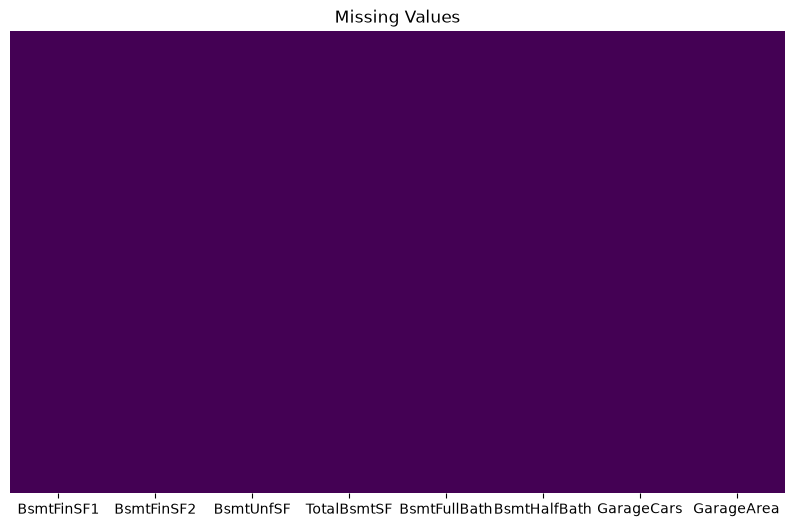

In [215]:
missing_cols = test_df.columns[test_df.isnull().any()]

plt.figure(figsize=(10, 6))

sns.heatmap(
    df[missing_cols].isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values")
plt.show()

In [234]:
test_df['MasVnrArea'] = test_df['MasVnrArea'].fillna(0.0)
test_df['BsmtFinSF1'] = test_df['BsmtFinSF1'].fillna(0.0)
test_df['BsmtFinSF2'] = test_df['BsmtFinSF2'].fillna(0.0)
test_df['BsmtUnfSF'] = test_df['BsmtUnfSF'].fillna(0.0)
test_df['TotalBsmtSF'] = test_df['TotalBsmtSF'].fillna(0.0)
test_df['BsmtFullBath'] = test_df['BsmtFullBath'].fillna(0.0)
test_df['BsmtHalfBath'] = test_df['BsmtHalfBath'].fillna(0.0)
test_df['GarageCars'] = test_df['GarageCars'].fillna(0.0)
test_df['GarageArea'] = test_df['GarageArea'].fillna(0.0)

In [235]:
test_df['GarageArea'].isnull().sum()

np.int64(0)

In [233]:
test_df['GarageArea'].value_counts()


GarageArea
0.0      76
576.0    50
440.0    47
484.0    34
400.0    33
         ..
609.0     1
272.0     1
518.0     1
714.0     1
682.0     1
Name: count, Length: 459, dtype: int64

In [ ]:
# test_df = test_df.dropna()

In [236]:
test_pred = model.predict(test_df)

In [237]:
submission = pd.DataFrame({
    'Id': test_df['Id'],
    'SalePrice': test_pred
})

submission.to_csv('submission.csv', index=False)